# Complete ARIMAX + Weather Forecasting Notebook

**ARIMAX = AutoRegressive Integrated Moving Average with Exogenous variables.**

This notebook does the full workflow:

```text
City name
  ↓
Open-Meteo Geocoding API
  ↓
Latitude + longitude
  ↓
Open-Meteo Historical Weather API
  ↓
Temperature + rainfall
  ↓
Merge with daily sales
  ↓
Choose (p,d,q)
  ↓
Train ARIMA baseline
  ↓
Train ARIMAX with weather
  ↓
Compare errors
  ↓
Inspect learned coefficients
  ↓
Fetch future weather
  ↓
Forecast future sales
```

There is **no seasonality** in this notebook.

It has two modes:

1. `USE_DEMO_SALES = True` → generates demo sales from real downloaded weather, so the notebook runs immediately.
2. `USE_DEMO_SALES = False` → reads your own `sales.csv` with columns `date,sales`.


## 1. Install packages

In [1]:
%pip install pandas numpy matplotlib statsmodels scikit-learn requests -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Imports

In [2]:
import warnings
warnings.filterwarnings("ignore")

from datetime import date, timedelta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error

## 3. Configuration

Change `CITY` to the business location.

Keep demo mode on for the first run. When you have real sales, set `USE_DEMO_SALES = False` and place `sales.csv` next to the notebook.


In [5]:
CITY = "Kozhikode"
USE_DEMO_SALES = True
SALES_CSV = "sales.csv"

HISTORY_DAYS = 730
HISTORY_LAG_DAYS = 7

today = date.today()
END_DATE = today - timedelta(days=HISTORY_LAG_DAYS)
START_DATE = END_DATE - timedelta(days=HISTORY_DAYS - 1)

print("Historical range:", START_DATE, "to", END_DATE)

Historical range: 2024-08-01 to 2026-07-31


## 4. Convert city name to latitude and longitude

In [6]:
def geocode_city(city):
    url = "https://geocoding-api.open-meteo.com/v1/search"
    params = {
        "name": city,
        "count": 1,
        "language": "en",
        "format": "json",
    }
    r = requests.get(url, params=params, timeout=30)
    r.raise_for_status()
    data = r.json()
    if not data.get("results"):
        raise ValueError(f"No location found for {city}")
    x = data["results"][0]
    return {
        "name": x.get("name"),
        "country": x.get("country"),
        "admin1": x.get("admin1"),
        "latitude": x["latitude"],
        "longitude": x["longitude"],
        "timezone": x.get("timezone"),
    }

location = geocode_city(CITY)
location

{'name': 'Kozhikode',
 'country': 'India',
 'admin1': 'Kerala',
 'latitude': 11.24802,
 'longitude': 75.7804,
 'timezone': 'Asia/Kolkata'}

In [7]:
latitude = location["latitude"]
longitude = location["longitude"]
print("Location:", location["name"], location.get("admin1"), location.get("country"))
print("Latitude:", latitude)
print("Longitude:", longitude)
print("Timezone:", location.get("timezone"))

Location: Kozhikode Kerala India
Latitude: 11.24802
Longitude: 75.7804
Timezone: Asia/Kolkata


## 5. Download historical weather directly

We download:
- daily mean temperature
- daily precipitation sum


In [8]:
def get_historical_weather(latitude, longitude, start_date, end_date):
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": str(start_date),
        "end_date": str(end_date),
        "daily": ["temperature_2m_mean", "precipitation_sum"],
        "timezone": "auto",
    }
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    data = r.json()
    if "daily" not in data:
        raise RuntimeError(data)
    return pd.DataFrame({
        "date": pd.to_datetime(data["daily"]["time"]),
        "temperature": data["daily"]["temperature_2m_mean"],
        "rainfall": data["daily"]["precipitation_sum"],
    })

weather_df = get_historical_weather(latitude, longitude, START_DATE, END_DATE)
print(weather_df.shape)
weather_df.head()

(730, 3)


,date,temperature,rainfall
0,2024-08-01,24.5,45.9
1,2024-08-02,25.4,6.6
2,2024-08-03,25.6,14.1
3,2024-08-04,25.9,15.4
4,2024-08-05,25.7,19.5


## 6. Inspect weather

In [9]:
print(weather_df.isna().sum())
print(weather_df[["temperature", "rainfall"]].describe())

date           0
temperature    0
rainfall       0
dtype: int64
       temperature    rainfall
count   730.000000  730.000000
mean     26.465342    8.958767
std       1.178763   13.076190
min      23.800000    0.000000
25%      25.600000    0.400000
50%      26.400000    3.800000
75%      27.300000   12.975000
max      29.700000   77.800000


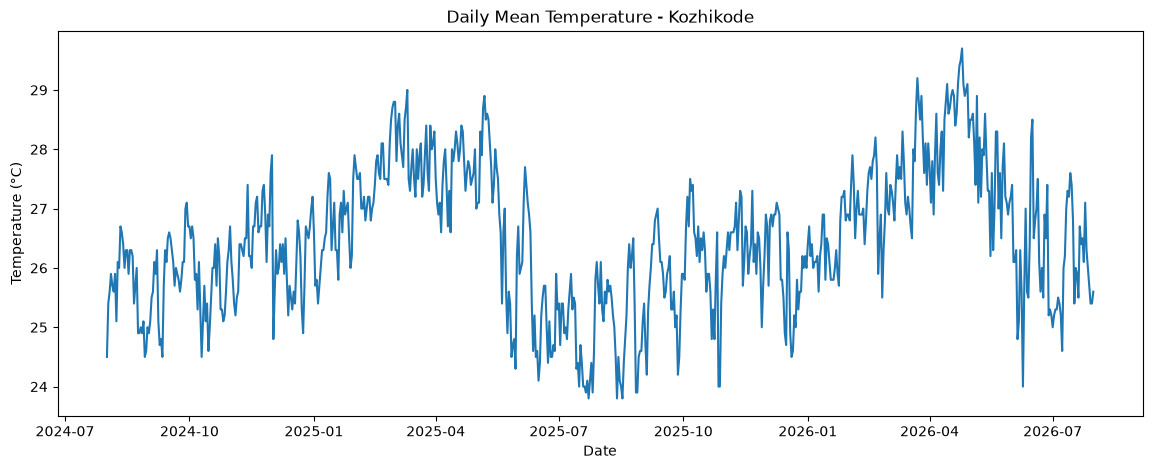

In [10]:
plt.figure(figsize=(14,5))
plt.plot(weather_df["date"], weather_df["temperature"])
plt.title(f"Daily Mean Temperature - {CITY}")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.show()

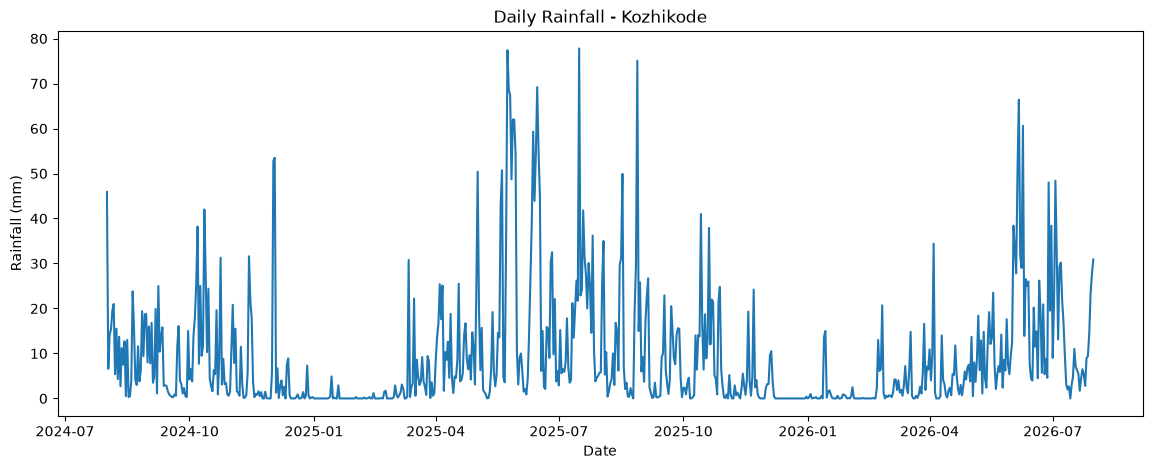

In [11]:
plt.figure(figsize=(14,5))
plt.plot(weather_df["date"], weather_df["rainfall"])
plt.title(f"Daily Rainfall - {CITY}")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.show()

## 7. Sales data

In demo mode, sales are generated from real weather with **no seasonal term**. This is only so you can see whether ARIMAX recovers the weather relationship.

For real data, use a CSV like:

```text
date,sales
2026-01-01,120
2026-01-02,131
```


In [14]:
def create_demo_sales(weather):
    rng = np.random.default_rng(42)
    n = len(weather)
    t = np.arange(n)

    ar_noise = np.zeros(n)
    shocks = rng.normal(0, 8, n)
    for i in range(1, n):
        ar_noise[i] = 0.55 * ar_noise[i-1] + shocks[i]

    sales = (
        180
        + 0.05 * t
        + 2.2 * weather["temperature"].to_numpy()
        - 1.4 * weather["rainfall"].to_numpy()
        + ar_noise
    )
    sales = np.maximum(sales, 0)

    return pd.DataFrame({
        "date": weather["date"],
        "sales": np.round(sales, 0),
    })

if USE_DEMO_SALES:
    sales_df = create_demo_sales(weather_df)
    print("DEMO mode")
else:
    sales_df = pd.read_csv(SALES_CSV)
    sales_df["date"] = pd.to_datetime(sales_df["date"])
    if "sales" not in sales_df.columns:
        raise ValueError("sales.csv must contain date and sales columns")
    sales_df = sales_df.groupby("date", as_index=False)["sales"].sum().sort_values("date")
    print("REAL sales mode")

sales_df.head()

DEMO mode


,date,sales
0,2024-08-01,170.0
1,2024-08-02,218.0
2,2024-08-03,218.0
3,2024-08-04,224.0
4,2024-08-05,198.0


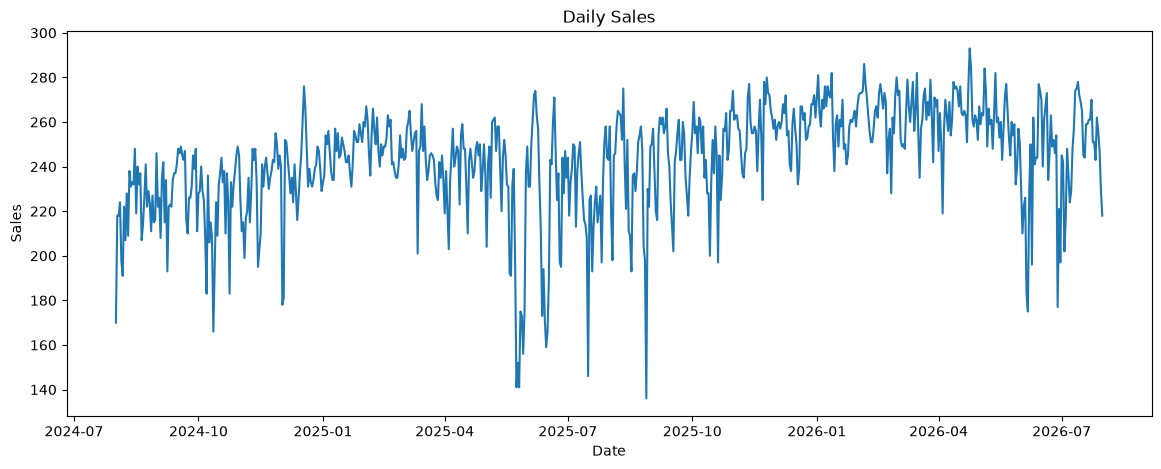

In [15]:
plt.figure(figsize=(14,5))
plt.plot(sales_df["date"], sales_df["sales"])
plt.title("Daily Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.show()

## 8. Merge sales and weather by date

In [16]:
df = pd.merge(sales_df, weather_df, on="date", how="inner")
df = df.sort_values("date").drop_duplicates("date").reset_index(drop=True)
df = df.dropna(subset=["sales", "temperature", "rainfall"]).reset_index(drop=True)
print(df.shape)
df.head(10)

(730, 4)


,date,sales,temperature,rainfall
0,2024-08-01,170.0,24.5,45.9
1,2024-08-02,218.0,25.4,6.6
2,2024-08-03,218.0,25.6,14.1
3,2024-08-04,224.0,25.9,15.4
4,2024-08-05,198.0,25.7,19.5
5,2024-08-06,191.0,25.6,21.0
6,2024-08-07,222.0,25.9,5.4
7,2024-08-08,207.0,25.1,15.5
8,2024-08-09,228.0,26.1,4.3
9,2024-08-10,209.0,26.0,13.7


## 9. Quick relationship checks

In [17]:
print(df[["sales", "temperature", "rainfall"]].corr())

                sales  temperature  rainfall
sales        1.000000     0.535551 -0.798768
temperature  0.535551     1.000000 -0.463960
rainfall    -0.798768    -0.463960  1.000000


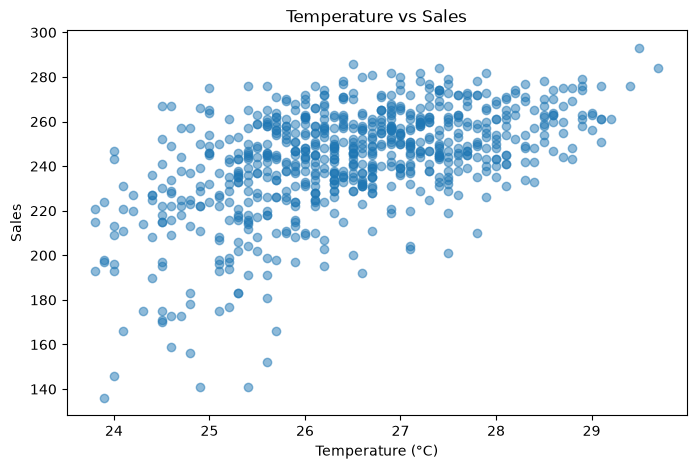

In [18]:
plt.figure(figsize=(8,5))
plt.scatter(df["temperature"], df["sales"], alpha=0.5)
plt.title("Temperature vs Sales")
plt.xlabel("Temperature (°C)")
plt.ylabel("Sales")
plt.show()

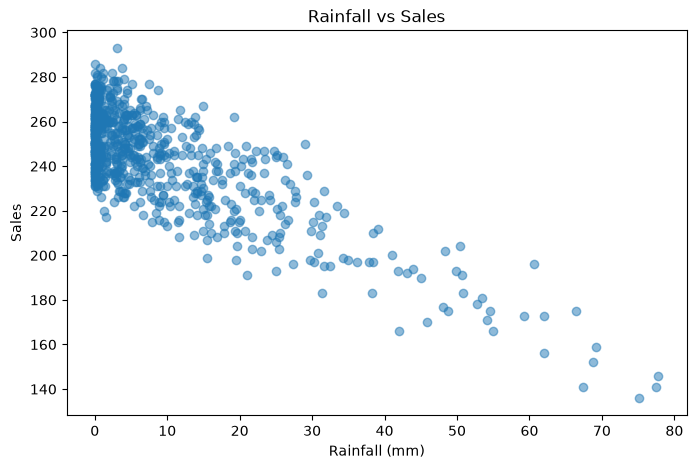

In [19]:
plt.figure(figsize=(8,5))
plt.scatter(df["rainfall"], df["sales"], alpha=0.5)
plt.title("Rainfall vs Sales")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Sales")
plt.show()

## 10. Find a candidate `d`

The Augmented Dickey-Fuller test is one diagnostic for stationarity.

Very roughly:
- p-value below 0.05 → evidence of stationarity
- p-value above or equal to 0.05 → consider differencing


In [20]:
def adf_report(series, name):
    x = pd.Series(series).dropna()
    statistic, pvalue, used_lag, nobs, critical_values, _ = adfuller(x)
    print(name)
    print("ADF statistic:", round(statistic, 4))
    print("p-value:", round(pvalue, 6))
    print("used lags:", used_lag)
    print("observations:", nobs)
    print("critical values:", critical_values)
    print()

adf_report(df["sales"], "Original sales")
adf_report(df["sales"].diff().dropna(), "First-differenced sales")

Original sales
ADF statistic: -3.4332
p-value: 0.009879
used lags: 16
observations: 713
critical values: {'1%': np.float64(-3.43955476721974), '5%': np.float64(-2.865602155751202), '10%': np.float64(-2.5689331692727135)}

First-differenced sales
ADF statistic: -10.7952
p-value: 0.0
used lags: 16
observations: 712
critical values: {'1%': np.float64(-3.4395677423210493), '5%': np.float64(-2.8656078730509784), '10%': np.float64(-2.5689362152032573)}



## 11. Autocorrelation Function and Partial Autocorrelation Function hints for `q` and `p`

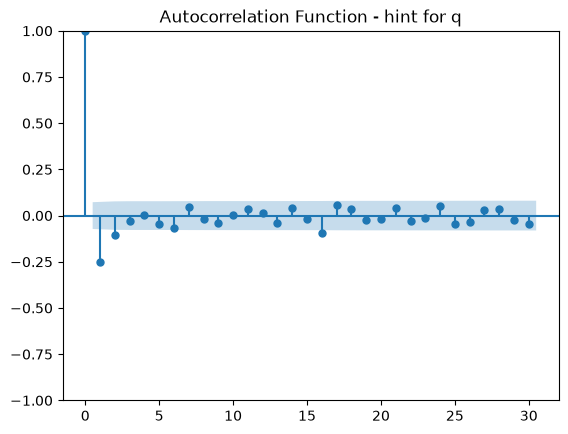

In [21]:
series_for_lags = df["sales"].diff().dropna()
plot_acf(series_for_lags, lags=30)
plt.title("Autocorrelation Function - hint for q")
plt.show()

In [ ]:
plot_pacf(series_for_lags, lags=30, method="ywm")
plt.title("Partial Autocorrelation Function - hint for p")
plt.show()

## 12. Start with a candidate order

For the first run we use `ARIMAX(1,1,1)`.


In [22]:
P = 1
D = 1
Q = 1
ORDER = (P, D, Q)
print("Candidate order:", ORDER)

Candidate order: (1, 1, 1)


## 13. Chronological train/test split

In [23]:
TEST_DAYS = 60
FEATURES = ["temperature", "rainfall"]

if len(df) <= TEST_DAYS + 30:
    raise ValueError("Not enough rows")

train = df.iloc[:-TEST_DAYS].copy()
test = df.iloc[-TEST_DAYS:].copy()

print("Train:", train["date"].min(), "to", train["date"].max(), len(train), "rows")
print("Test :", test["date"].min(), "to", test["date"].max(), len(test), "rows")

Train: 2024-08-01 00:00:00 to 2026-06-01 00:00:00 670 rows
Test : 2026-06-02 00:00:00 to 2026-07-31 00:00:00 60 rows


## 14. Plain ARIMA baseline

This model gets **sales only**. It does not get weather.


In [24]:
arima_fit = ARIMA(train["sales"], order=ORDER).fit()
print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  sales   No. Observations:                  670
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -2800.640
Date:                Fri, 07 Aug 2026   AIC                           5607.280
Time:                        16:52:33   BIC                           5620.798
Sample:                             0   HQIC                          5612.516
                                - 670                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5588      0.025     22.195      0.000       0.509       0.608
ma.L1         -0.9627      0.011    -86.405      0.000      -0.985      -0.941
sigma2       252.7900      9.268     27.275      0.0

In [25]:
arima_forecast = arima_fit.forecast(steps=len(test))
test["arima_prediction"] = np.asarray(arima_forecast)

## 15. ARIMAX with weather

`endog` is the target: sales.

`exog` is the external data: temperature and rainfall.


In [26]:
arimax_fit = ARIMA(
    endog=train["sales"],
    exog=train[FEATURES],
    order=ORDER,
).fit()

print(arimax_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  sales   No. Observations:                  670
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -2338.470
Date:                Fri, 07 Aug 2026   AIC                           4686.939
Time:                        16:52:57   BIC                           4709.468
Sample:                             0   HQIC                          4695.666
                                - 670                                         
Covariance Type:                  opg                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
temperature     2.2663      0.574      3.950      0.000       1.142       3.391
rainfall       -1.3741      0.035    -39.437      0.000      -1.442      -1.306
ar.L1           0.5677      0.035     16.421    

## 16. See the learned pattern

In [27]:
print(arimax_fit.params)

temperature     2.266314
rainfall       -1.374105
ar.L1           0.567674
ma.L1          -0.974602
sigma2         63.459198
dtype: float64


Typical parameter names:

```text
temperature   -> learned temperature relationship
rainfall      -> learned rainfall relationship
ar.L1         -> AutoRegressive lag-1 coefficient
ma.L1         -> Moving Average lag-1 coefficient
sigma2        -> residual variance
```

A positive weather coefficient means higher values are associated with higher sales, holding the rest of the model constant. A negative coefficient means the opposite. This is association, not automatic proof of causation.


## 17. Forecast the test period with weather

In [28]:
arimax_forecast = arimax_fit.forecast(
    steps=len(test),
    exog=test[FEATURES],
)

test["arimax_prediction"] = np.asarray(arimax_forecast)

test[["date", "sales", "temperature", "rainfall", "arima_prediction", "arimax_prediction"]].head(10)

,date,sales,temperature,rainfall,arima_prediction,arimax_prediction
670,2026-06-02,210.0,26.1,38.4,242.541654,200.969229
671,2026-06-03,222.0,26.1,33.4,248.991577,212.667674
672,2026-06-04,226.0,26.3,27.8,252.596044,223.556607
673,2026-06-05,183.0,24.8,50.8,254.610360,190.108542
674,2026-06-06,175.0,25.1,66.4,255.736037,170.235597
675,2026-06-07,229.0,26.3,31.7,256.365110,221.137973
676,2026-06-08,250.0,25.6,29.0,256.716660,223.546248
677,2026-06-09,196.0,24.0,60.6,256.913119,176.660005
678,2026-06-10,262.0,25.7,13.9,257.022909,244.775145
679,2026-06-11,241.0,27.0,26.5,257.084263,230.459699


## 18. Evaluate ARIMA vs ARIMAX

In [29]:
def wape(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    denom = np.sum(np.abs(actual))
    return np.nan if denom == 0 else np.sum(np.abs(actual - predicted)) / denom * 100

def metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "WAPE (%)": wape(actual, predicted),
    }

comparison = pd.DataFrame([
    {"Model": "ARIMA - no weather", **metrics(test["sales"], test["arima_prediction"])},
    {"Model": "ARIMAX - weather", **metrics(test["sales"], test["arimax_prediction"])},
])

comparison

,Model,MAE,RMSE,WAPE (%)
0,ARIMA - no weather,19.907219,27.478109,8.169857
1,ARIMAX - weather,9.109349,10.711858,3.738447


Lower error is better. If ARIMAX beats ARIMA on unseen dates, weather is adding useful predictive information for this test period.

## 19. Plot predictions

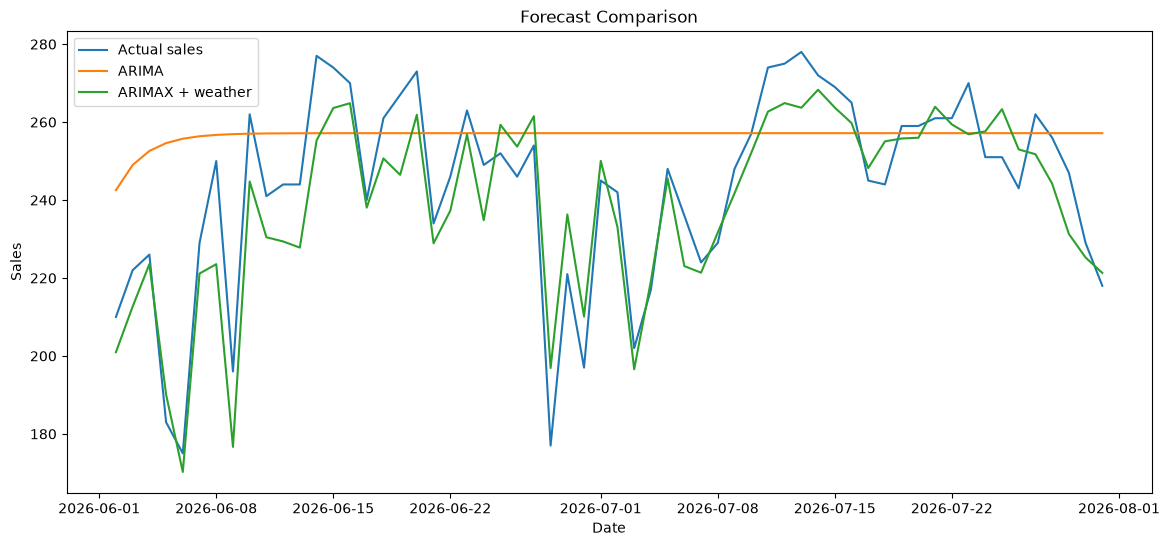

In [30]:
plt.figure(figsize=(14,6))
plt.plot(test["date"], test["sales"], label="Actual sales")
plt.plot(test["date"], test["arima_prediction"], label="ARIMA")
plt.plot(test["date"], test["arimax_prediction"], label="ARIMAX + weather")
plt.title("Forecast Comparison")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.show()

## 20. Residual diagnostics

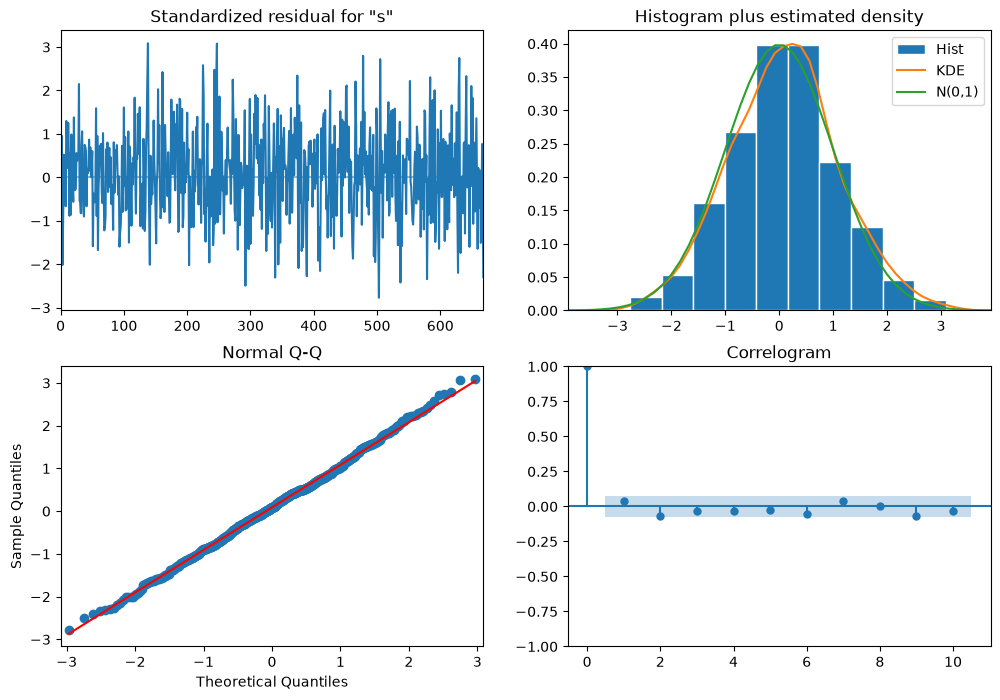

In [31]:
arimax_fit.plot_diagnostics(figsize=(12,8))
plt.show()

## 21. Test several `(p,d,q)` combinations

Autocorrelation Function and Partial Autocorrelation Function give candidates. We still backtest nearby combinations on the future holdout period.


In [32]:
candidate_p = [0,1,2]
candidate_d = [0,1]
candidate_q = [0,1,2]

rows = []
for p in candidate_p:
    for d in candidate_d:
        for q in candidate_q:
            order = (p,d,q)
            try:
                fit = ARIMA(
                    endog=train["sales"],
                    exog=train[FEATURES],
                    order=order,
                ).fit()
                pred = fit.forecast(steps=len(test), exog=test[FEATURES])
                m = metrics(test["sales"], pred)
                rows.append({
                    "p": p, "d": d, "q": q,
                    "MAE": m["MAE"],
                    "RMSE": m["RMSE"],
                    "WAPE (%)": m["WAPE (%)"],
                    "AIC": fit.aic,
                })
            except Exception as e:
                print("Skipped", order, e)

grid_results = pd.DataFrame(rows).sort_values("WAPE (%)").reset_index(drop=True)
grid_results.head(10)

c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


,p,d,q,MAE,RMSE,WAPE (%),AIC
0,2,1,1,9.029687,10.646450,3.705754,4684.378466
1,1,1,2,9.041219,10.656754,3.710486,4684.371625
2,0,1,2,9.046642,10.730183,3.712712,4721.589273
3,1,1,1,9.109349,10.711858,3.738447,4686.939209
4,2,1,2,9.139829,10.747335,3.750956,4686.676595
5,2,0,2,9.187344,10.813487,3.770456,4698.231279
6,1,0,2,9.482946,11.245593,3.891770,4733.070856
7,0,0,1,16.479627,18.750590,6.763185,4981.021158
8,0,0,0,16.566917,18.906823,6.799008,5351.570637
9,0,0,2,16.692075,18.959223,6.850373,4870.455561


## 22. Pick the best tested order

In [33]:
best = grid_results.iloc[0]
BEST_ORDER = (int(best["p"]), int(best["d"]), int(best["q"]))
print("Best order:", BEST_ORDER)
print(best)

Best order: (2, 1, 1)
p              2.000000
d              1.000000
q              1.000000
MAE            9.029687
RMSE          10.646450
WAPE (%)       3.705754
AIC         4684.378466
Name: 0, dtype: float64


## 23. Refit on all historical data

In [36]:
final_fit = ARIMA(
    endog=df["sales"],
    exog=df[FEATURES],
    order=BEST_ORDER,
).fit()

print(final_fit.summary())
print("Final parameters:", final_fit.params)

                               SARIMAX Results                                
Dep. Variable:                  sales   No. Observations:                  730
Model:                 ARIMA(2, 1, 1)   Log Likelihood               -2545.364
Date:                Fri, 07 Aug 2026   AIC                           5102.728
Time:                        17:03:33   BIC                           5130.278
Sample:                             0   HQIC                          5113.358
                                - 730                                         
Covariance Type:                  opg                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
temperature     2.1645      0.531      4.073      0.000       1.123       3.206
rainfall       -1.3736      0.032    -42.683      0.000      -1.437      -1.311
ar.L1           0.6155      0.038     16.249    

## 24. Download weather for dates after the training period

Future ARIMAX forecasting needs future values for the external variables. Here we use Open-Meteo's forecast endpoint.


In [37]:
def get_forecast_weather(latitude, longitude, past_days=7, forecast_days=7):
    url = "https://api.open-meteo.com/v1/forecast"
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "daily": ["temperature_2m_mean", "precipitation_sum"],
        "timezone": "auto",
        "past_days": past_days,
        "forecast_days": forecast_days,
    }
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    data = r.json()
    if "daily" not in data:
        raise RuntimeError(data)
    return pd.DataFrame({
        "date": pd.to_datetime(data["daily"]["time"]),
        "temperature": data["daily"]["temperature_2m_mean"],
        "rainfall": data["daily"]["precipitation_sum"],
    })

available_weather = get_forecast_weather(
    latitude,
    longitude,
    past_days=HISTORY_LAG_DAYS,
    forecast_days=7,
)
available_weather

,date,temperature,rainfall
0,2026-07-31,25.6,30.9
1,2026-08-01,24.3,145.9
2,2026-08-02,25.0,39.4
3,2026-08-03,24.8,43.0
4,2026-08-04,25.0,22.1
5,2026-08-05,25.7,6.2
6,2026-08-06,25.5,15.9
7,2026-08-07,24.3,41.5
8,2026-08-08,25.1,6.4
9,2026-08-09,25.2,3.0


## 25. Keep only weather after the final training date

In [38]:
last_training_date = df["date"].max()
future_weather = (
    available_weather[available_weather["date"] > last_training_date]
    .dropna(subset=FEATURES)
    .sort_values("date")
    .reset_index(drop=True)
)

print("Last training date:", last_training_date)
print("Forecast steps:", len(future_weather))
future_weather

Last training date: 2026-07-31 00:00:00
Forecast steps: 13


,date,temperature,rainfall
0,2026-08-01,24.3,145.9
1,2026-08-02,25.0,39.4
2,2026-08-03,24.8,43.0
3,2026-08-04,25.0,22.1
4,2026-08-05,25.7,6.2
5,2026-08-06,25.5,15.9
6,2026-08-07,24.3,41.5
7,2026-08-08,25.1,6.4
8,2026-08-09,25.2,3.0
9,2026-08-10,25.4,4.0


## 26. Forecast future sales

In [41]:
if future_weather.empty:
    raise ValueError("No weather rows available after the training date. Adjust HISTORY_LAG_DAYS.")

future_sales = final_fit.forecast(
    steps=len(future_weather),
    exog=future_weather[FEATURES],
)

future_result = future_weather.copy()
future_result["predicted_sales"] = np.asarray(future_sales)
future_result

,date,temperature,rainfall,predicted_sales
0,2026-08-01,24.3,145.9,59.414594
1,2026-08-02,25.0,39.4,209.159883
2,2026-08-03,24.8,43.0,204.792481
3,2026-08-04,25.0,22.1,234.392547
4,2026-08-05,25.7,6.2,257.945484
5,2026-08-06,25.5,15.9,244.271609
6,2026-08-07,24.3,41.5,206.544437
7,2026-08-08,25.1,6.4,256.503818
8,2026-08-09,25.2,3.0,261.396398
9,2026-08-10,25.4,4.0,260.458102


## 27. Plot the future forecast

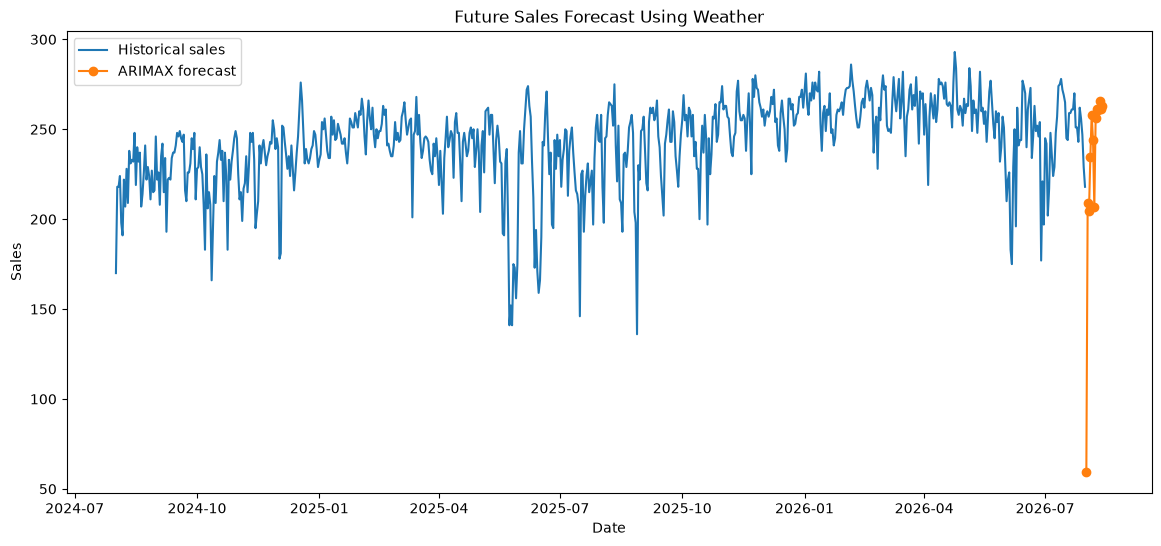

In [42]:
plt.figure(figsize=(14,6))
plt.plot(df["date"], df["sales"], label="Historical sales")
plt.plot(future_result["date"], future_result["predicted_sales"], marker="o", label="ARIMAX forecast")
plt.title("Future Sales Forecast Using Weather")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.show()

## 28. Save results

In [43]:
df.to_csv("arimax_training_data.csv", index=False)
future_result.to_csv("arimax_future_forecast.csv", index=False)
comparison.to_csv("arima_vs_arimax_metrics.csv", index=False)
grid_results.to_csv("arimax_pdq_search.csv", index=False)

print("Saved result CSV files.")

Saved result CSV files.


# Final mental model

```text
TRAINING

Historical sales
      +
Historical temperature
      +
Historical rainfall
      ↓
ARIMAX(p,d,q)
      ↓
Learned coefficients
```

```text
FUTURE PREDICTION

Learned ARIMAX
      +
Forecast temperature
      +
Forecast rainfall
      ↓
Future sales
```

There is **no seasonal model** here. Weather is being used only as external, exogenous information.

One important limitation: future sales predictions inherit some uncertainty from the weather forecast. The farther ahead the weather forecast is, the more that uncertainty can matter.
